# newcode1 — Optimized ESC-50 model

Two candidates were trained for 80 epochs on folds 1–3 and selected solely using fold 4. Candidate A won with **81% validation accuracy** (epoch 69); candidate B reached 80.25%. Only the selected candidate is tested below. Its saved model and training records are included in the repository.

Training used 16 kHz log-mel features, an eight-convolution network, time/frequency masking, AdamW, cosine scheduling, dropout and label smoothing. The selected model uses no mixup. See `docs/OPTIMIZATION.md` for full reproduction commands and limitations.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
MODEL = ROOT / "artifacts/optimized/audionet.ckpt"
selection = json.loads((ROOT / "artifacts/optimization_selection.json").read_text())
display(pd.DataFrame([{k:r[k] for k in ["candidate","validation_accuracy","selected_epoch"]} for r in selection["candidates"]]))
print("Selected by validation:",selection["winner"])

,candidate,validation_accuracy,selected_epoch
0,candidate-a,0.8100,69
1,candidate-b,0.8025,73


Selected by validation: candidate-a


In [2]:
from test import main as test_model
test_model(["--checkpoint", str(MODEL), "--output-dir", str(ROOT / "artifacts/optimized/test")])

Using cached features: C:\Users\ryan\Desktop\work folder\new code\data\cache\d4f85a90547025fcf486.pt


{
  "test_fold": 5,
  "samples": 400,
  "accuracy": 0.67,
  "loss": 1.2329133605957032,
  "selected_epoch": 69,
  "validation_accuracy": 0.81,
  "checkpoint": "C:\\Users\\ryan\\Desktop\\work folder\\new code\\artifacts\\optimized\\audionet.ckpt",
  "checkpoint_sha256": "2c97292a6aa16a5b1179bfa9d5fda55849f8b783274dc4de2461622cb2f46b9d",
  "environment": {
    "python": "3.12.11",
    "torch": "2.8.0+cu129",
    "torchaudio": "2.8.0+cu129",
    "numpy": "2.2.4",
    "device": "cuda",
    "gpu": "NVIDIA GeForce RTX 4060 Laptop GPU"
  },
  "chance_accuracy": 0.02,
  "macro_f1": 0.6546288826412665
}
Test results saved to C:\Users\ryan\Desktop\work folder\new code\artifacts\optimized\test


,samples,accuracy,validation_accuracy,selected_epoch,macro_f1
0,400,0.67,0.81,69,0.654629


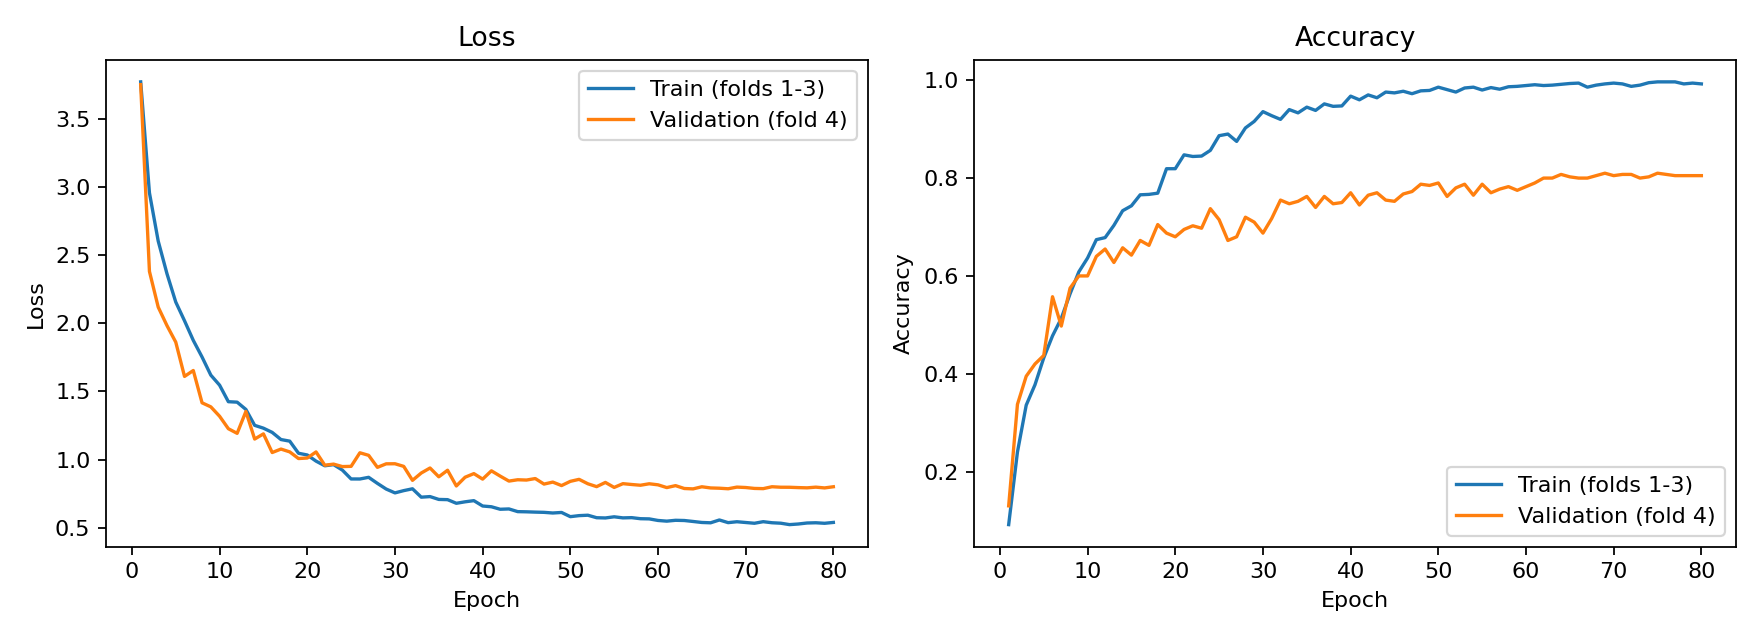

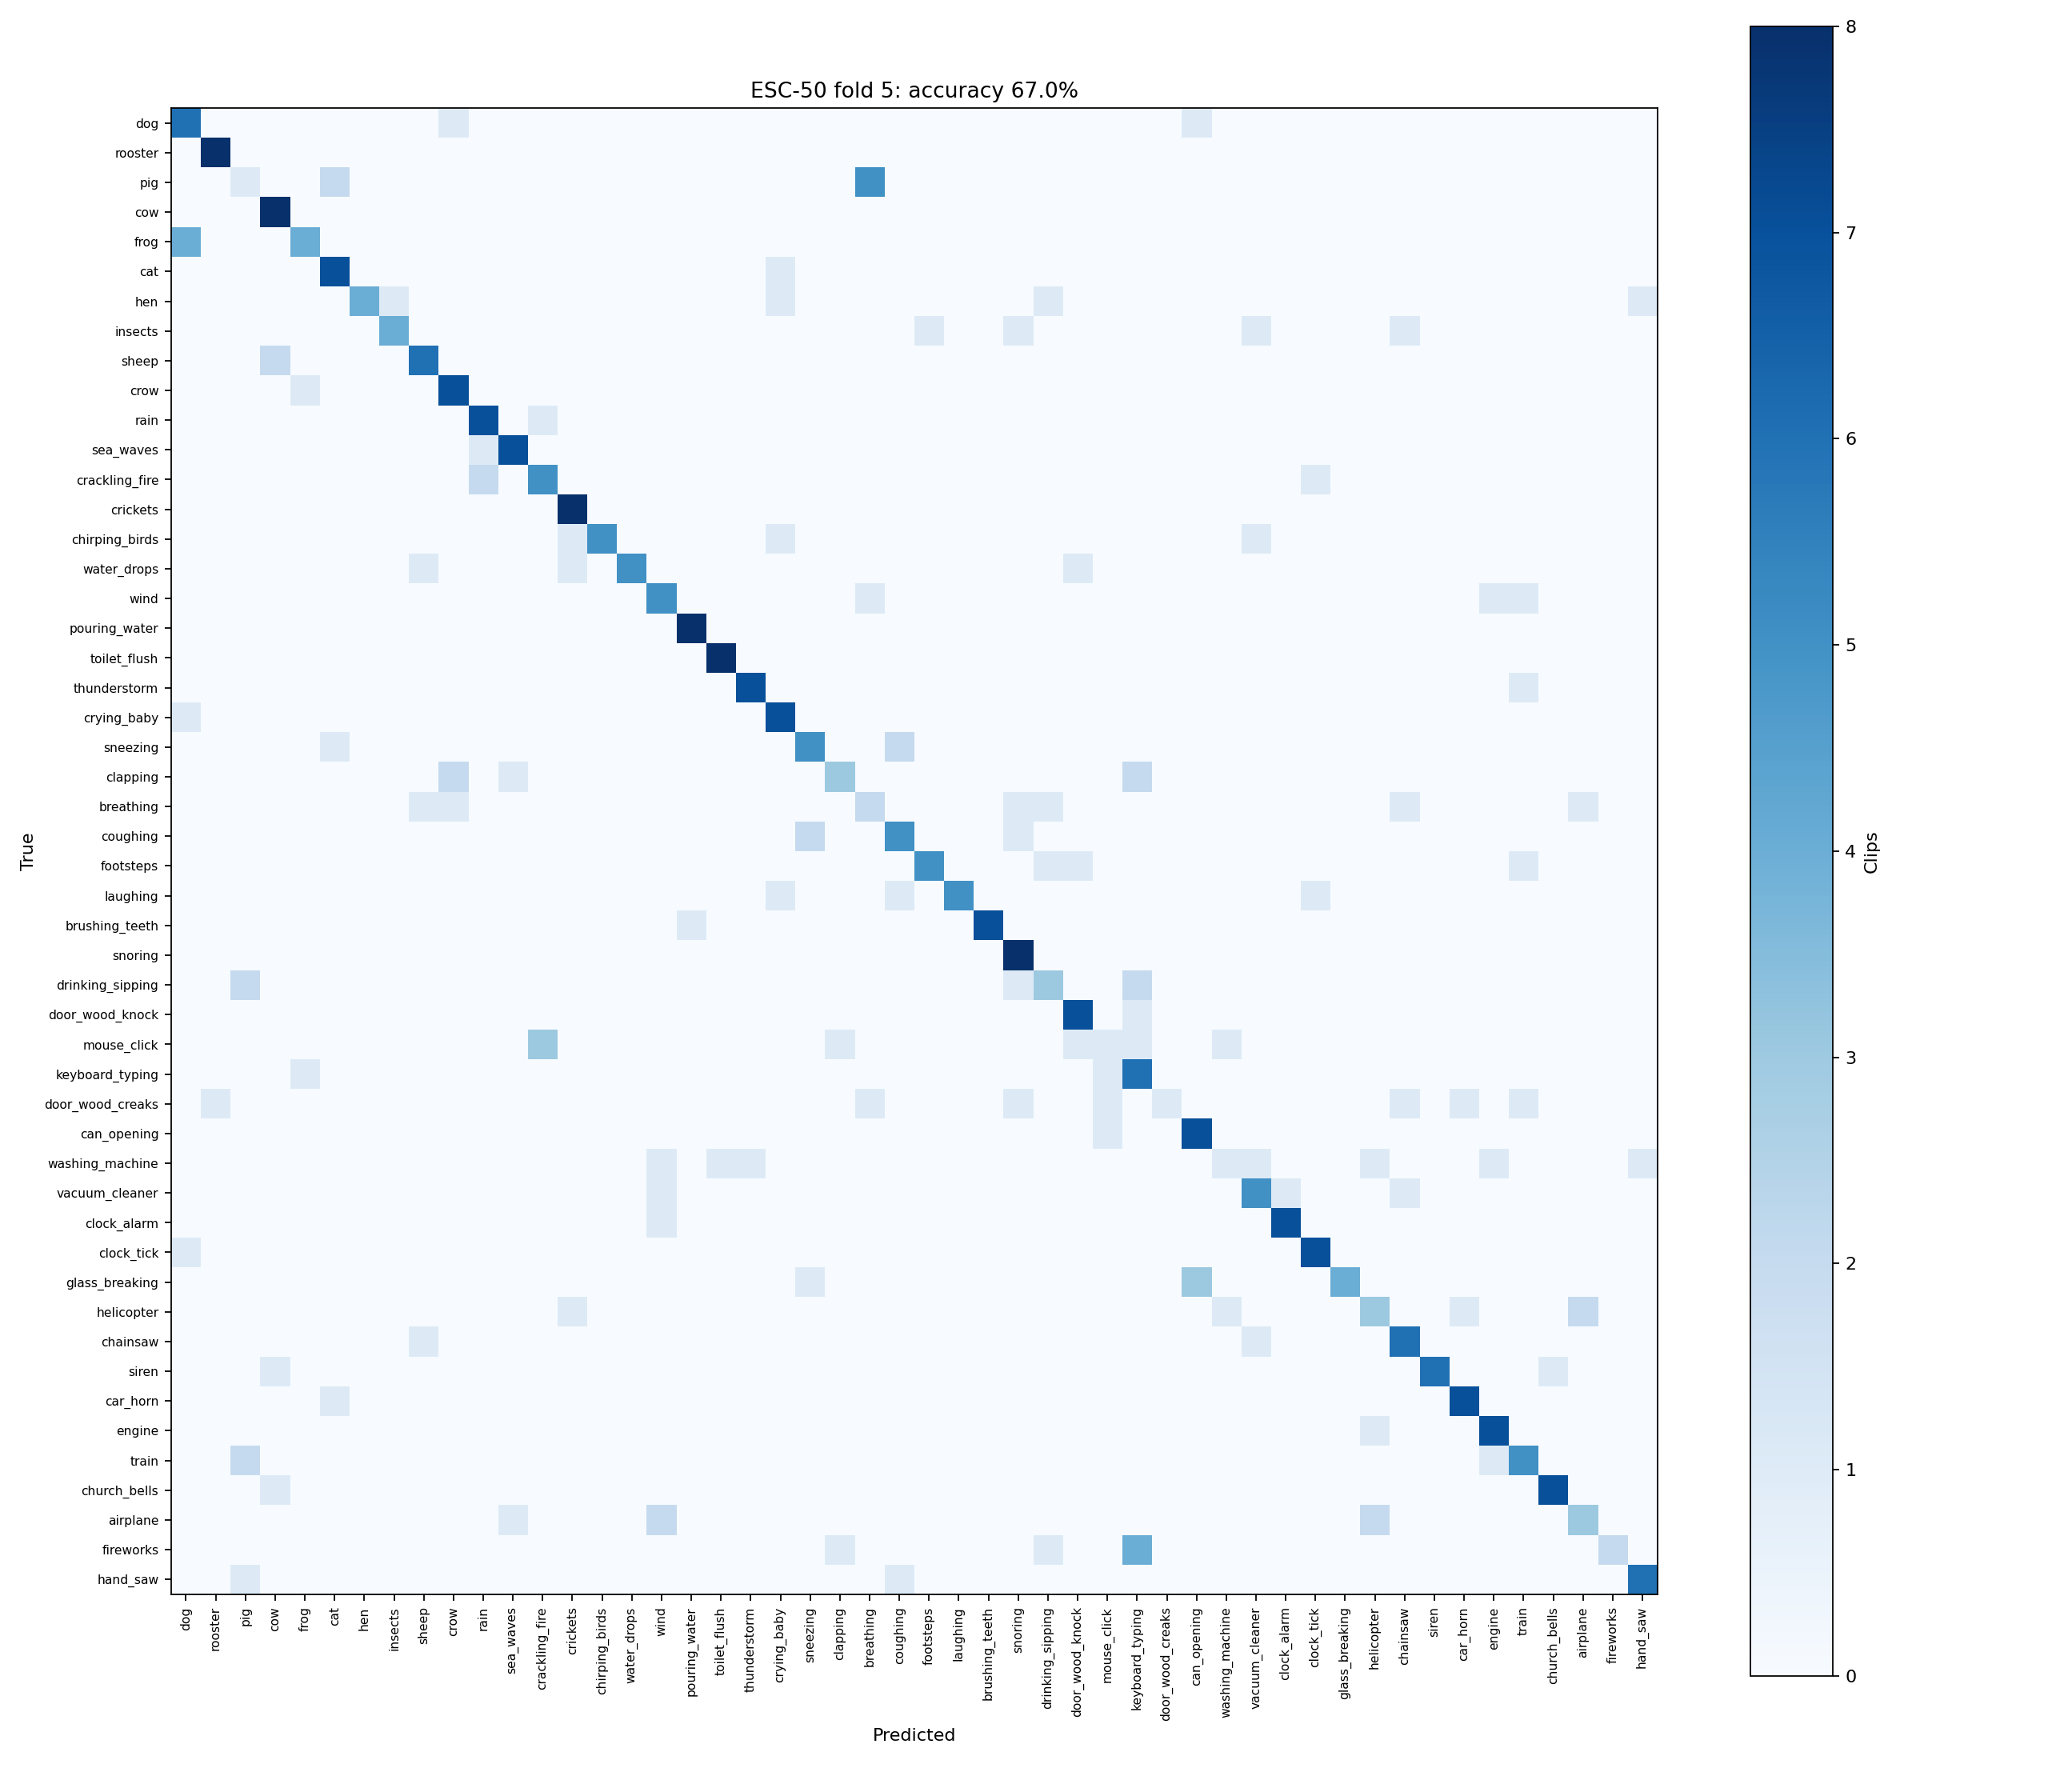

In [3]:
metrics = json.loads((ROOT / "artifacts/optimized/test/test_metrics.json").read_text())
display(pd.DataFrame([{k:metrics[k] for k in ["samples","accuracy","validation_accuracy","selected_epoch","macro_f1"]}]))
display(Image(filename=str(ROOT / "artifacts/optimized/training_curves.png")))
display(Image(filename=str(ROOT / "artifacts/optimized/test/confusion_matrix.png")))